In [1]:

# Import required library
import os
from pathlib import Path

# Display current working directory
print("Current Working Directory:")
print(Path.cwd())

# Display available files and folders
print("\nFiles and Folders:")
print(os.listdir())


Current Working Directory:
C:\Users\manid\ML_assignment2\Notebooks

Files and Folders:
['.ipynb_checkpoints', 'ML_Assignment2.ipynb', 'Untitled.ipynb']


In [2]:

from pathlib import Path

# Go one level up to the main project folder
project_path = Path.cwd().parent

print("Project Folder:", project_path)

print("\nContents of Project Folder:")
for item in project_path.iterdir():
    print(item.name)


Project Folder: C:\Users\manid\ML_assignment2

Contents of Project Folder:
.ipynb_checkpoints
.qodo
app.py
Data
Models
model_comparison.csv
Notebooks
requirement.txt
test_data.csv


In [3]:

# Display files inside the Data folder

data_path = project_path / "Data"

print("Dataset Folder:", data_path)

print("\nAvailable datasets:")
for file in data_path.iterdir():
    print(file.name)


Dataset Folder: C:\Users\manid\ML_assignment2\Data

Available datasets:
Dry_Bean_Dataset.xlsx


In [6]:

# Load the Dry Bean dataset using the correct filename

dataset_file = data_path / "Dry_Bean_Dataset.xlsx"
df = pd.read_excel(dataset_file)

# Display the first five records
print("First Five Records:")
display(df.head())

# Display the number of rows and columns
print("\nDataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())


First Five Records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Dataset Shape: (13611, 17)

Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']


In [7]:

# Display dataset information including data types and non-null values
print("DATASET INFORMATION")
df.info()

# Check the number of missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check the total number of missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# Check the number of duplicate records
print("\nDUPLICATE RECORDS")
print("Total Duplicates:", df.duplicated().sum())

# Display the distribution of target classes
print("\nTARGET CLASS DISTRIBUTION")
print(df['Class'].value_counts())

# Display the percentage distribution of each class
print("\nCLASS DISTRIBUTION IN PERCENTAGE")
print((df['Class'].value_counts(normalize=True) * 100).round(2))


DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: 

In [8]:

# Check the total number of missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Identify duplicate records
print("\nTotal Duplicate Records:", df.duplicated().sum())

# Display the number of records in each target class
print("\nTarget Class Distribution:")
print(df['Class'].value_counts())

# Display the percentage of each target class
print("\nTarget Class Percentage:")
print((df['Class'].value_counts(normalize=True) * 100).round(2))


Total Missing Values: 0

Total Duplicate Records: 68

Target Class Distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64

Target Class Percentage:
Class
DERMASON    26.05
SIRA        19.37
SEKER       14.89
HOROZ       14.17
CALI        11.98
BARBUNYA     9.71
BOMBAY       3.84
Name: proportion, dtype: float64


In [9]:

# Remove duplicate records from the dataset

print("Shape before removing duplicates:", df.shape)

# Remove duplicate rows
df = df.drop_duplicates()

# Reset the index after removing duplicates
df = df.reset_index(drop=True)

# Display the updated dataset shape
print("\nShape after removing duplicates:", df.shape)

# Verify that no duplicate records remain
print("\nRemaining Duplicate Records:", df.duplicated().sum())


Shape before removing duplicates: (13611, 17)

Shape after removing duplicates: (13543, 17)

Remaining Duplicate Records: 0


In [10]:

# Display statistical summary of all numerical features

print("STATISTICAL SUMMARY")
display(df.describe())

# Display the updated number of records in each bean class
print("\nUPDATED CLASS DISTRIBUTION")
print(df['Class'].value_counts())


STATISTICAL SUMMARY


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000
mean,53048.460385,854.993406,319.895602,202.365321,1.581075,0.750315,53767.986709,253.034094,0.749829,0.987152,0.873671,0.800352,0.006561,0.001719,0.644341,0.995078
std,29392.438324,214.722684,85.809260,45.051632,0.245245,0.091858,29844.248525,59.307709,0.048939,0.004650,0.059393,0.061464,0.001130,0.000595,0.098653,0.004347
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36282.500000,703.230000,253.086806,175.886357,1.430662,0.715144,36673.000000,214.933277,0.718735,0.985678,0.833410,0.763228,0.005893,0.001158,0.582517,0.993720
50%,44580.000000,793.896000,296.404589,192.491117,1.549860,0.763997,45122.000000,238.245711,0.759903,0.988288,0.883490,0.801514,0.006643,0.001700,0.642424,0.996393
75%,61382.000000,977.146500,376.312489,217.245403,1.703916,0.809671,62360.000000,279.560351,0.786849,0.990019,0.917031,0.834470,0.007270,0.002173,0.696341,0.997891
max,254616.000000,1985.370000,738.860153,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733



UPDATED CLASS DISTRIBUTION
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


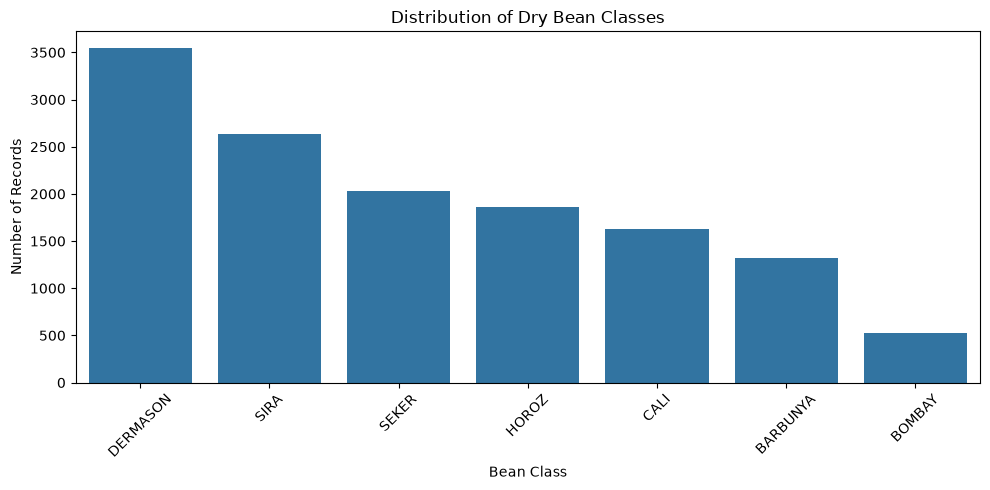

In [11]:

# Visualize the distribution of different bean classes

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='Class', order=df['Class'].value_counts().index)

# Add chart title and axis labels
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Records")

# Display the chart
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


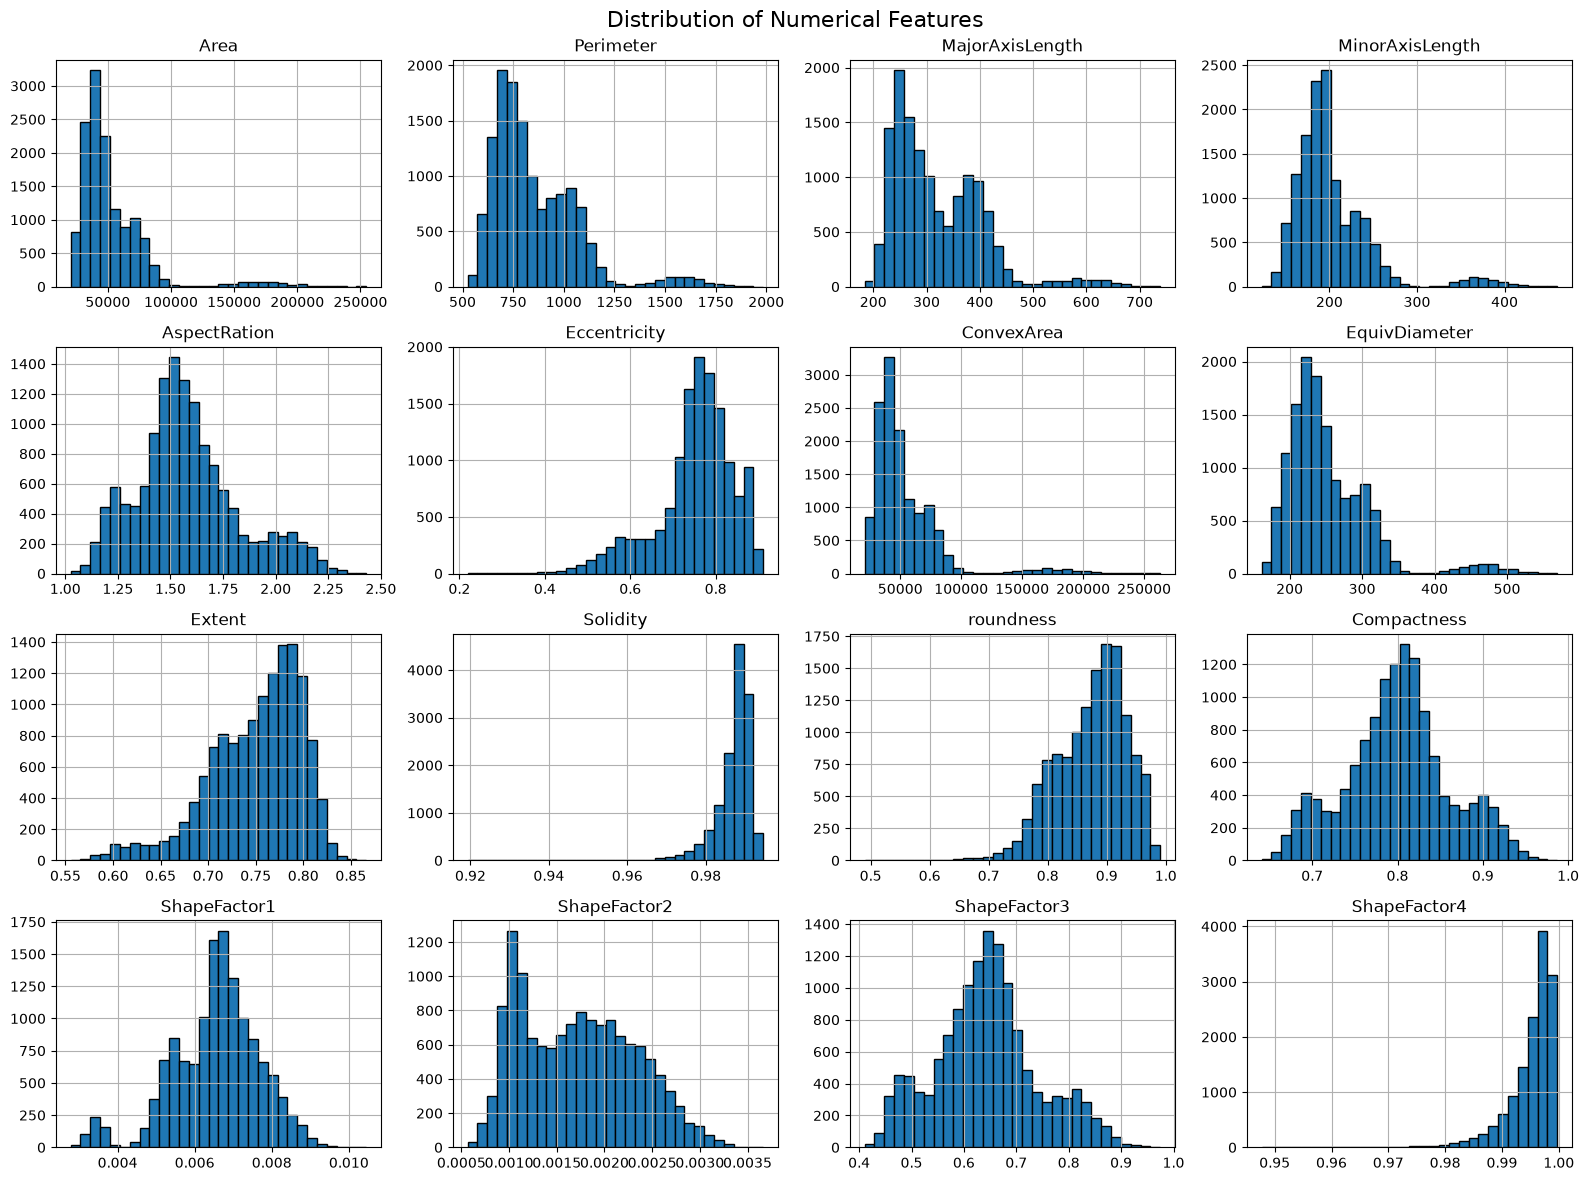

In [12]:

# Select all numerical input features, excluding the target column
numerical_features = df.drop(columns=['Class'])

# Plot histograms for all numerical features
numerical_features.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor='black'
)

# Add an overall title
plt.suptitle("Distribution of Numerical Features", fontsize=16)

# Adjust spacing between plots
plt.tight_layout()

# Display the histograms
plt.show()


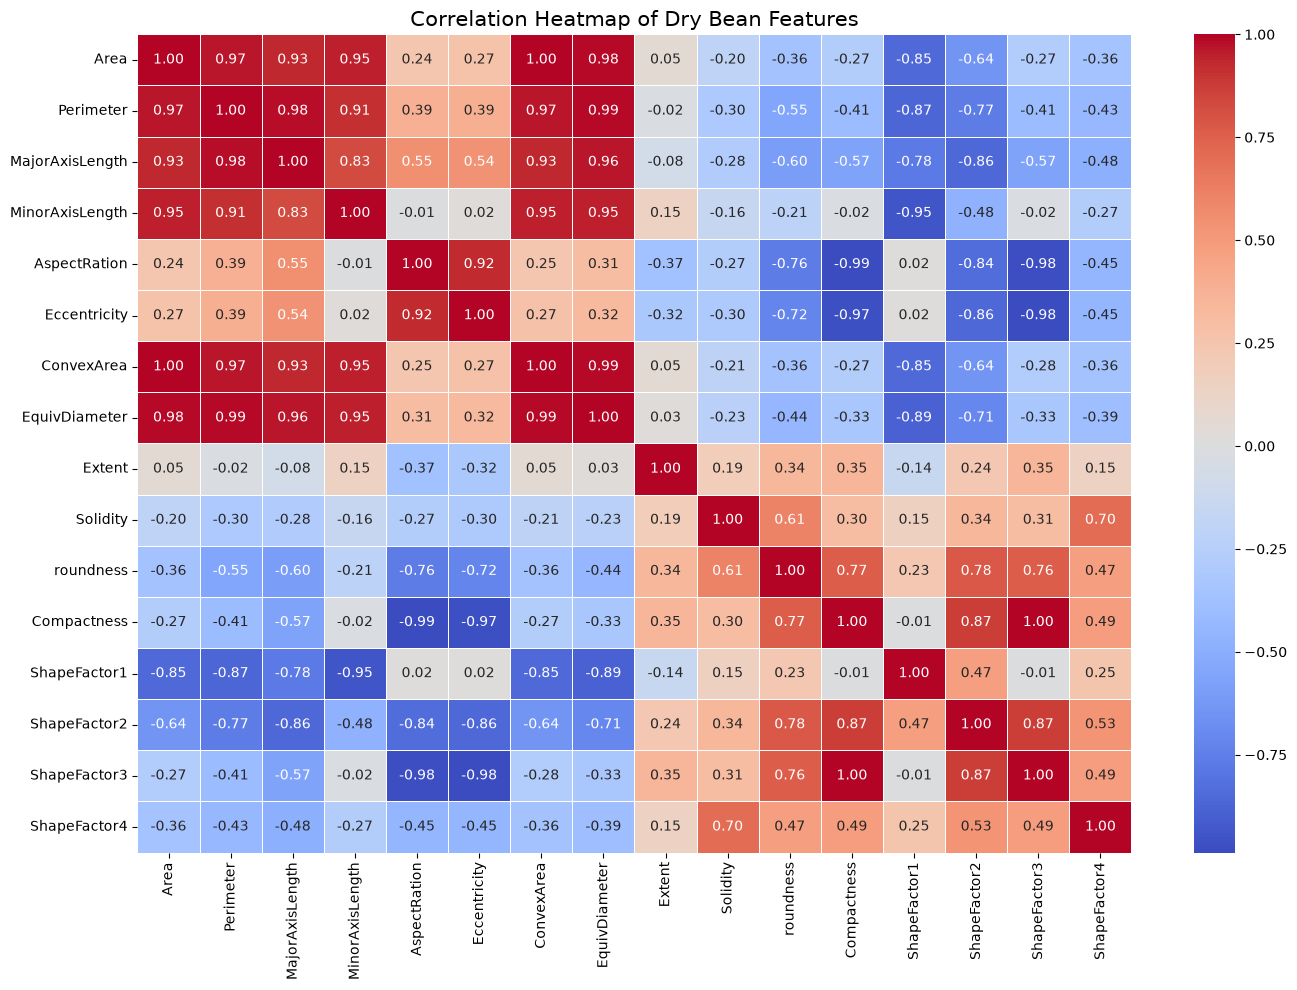

In [13]:

# Calculate the correlation between numerical features
correlation_matrix = df.drop(columns=['Class']).corr()

# Create a heatmap to visualize feature correlations
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# Add title
plt.title("Correlation Heatmap of Dry Bean Features", fontsize=15)

# Display the heatmap
plt.tight_layout()
plt.show()



## Exploratory Data Analysis – Observations and Insights

Based on the statistical analysis and visualizations performed on the Dry Bean dataset, the following observations were made:

### 1. Dataset Overview
- The dataset contains 13,543 records and 17 columns, including 16 numerical input features and one target variable (Class).
- No missing values were found in the dataset.
- A total of 68 duplicate records were identified and removed during data cleaning.

### 2. Class Distribution
- The dataset contains seven different bean classes: DERMASON, SIRA, SEKER, HOROZ, CALI, BARBUNYA and BOMBAY.
- DERMASON has the highest number of records, whereas BOMBAY has the lowest.
- The dataset has an imbalanced class distribution, which may influence classification performance.
- Stratified train-test splitting will be used to maintain class proportions during model evaluation.

### 3. Feature Distribution
- The histograms show that numerical features have different distributions and value ranges.
- Some features, such as Area and ConvexArea, exhibit positively skewed distributions.
- Certain features have concentrated distributions, while others show multiple peaks.
- Feature scaling will be considered for algorithms that are sensitive to differences in feature magnitudes.

### 4. Correlation Analysis
- Area, ConvexArea and EquivDiameter exhibit very strong positive correlations.
- AspectRatio and Eccentricity also show a strong positive correlation.
- Some shape-related features exhibit strong negative correlations with AspectRatio and Eccentricity.
- These relationships indicate that certain features may contain overlapping information.

### 5. Overall EDA Findings
- The dataset is suitable for a multi-class classification problem.
- Duplicate records have been removed, and no missing values are present.
- The target variable contains seven classes with unequal distributions.
- Feature scaling is important for models such as Logistic Regression, K-Nearest Neighbors and Support Vector Machine.
- The correlation analysis provides useful insights into relationships among numerical features.

### Conclusion
The exploratory data analysis helped understand the dataset structure, feature distributions, class imbalance and correlations among numerical variables. The cleaned dataset is now ready for preprocessing and implementation of the five classification algorithms.


In [14]:

# Separate independent features (X) and dependent target variable (y)

X = df.drop(columns=['Class'])
y = df['Class']

# Display the dimensions of features and target
print("Features Shape (X):", X.shape)
print("Target Shape (y):", y.shape)

# Display feature names
print("\nIndependent Features:")
print(X.columns.tolist())

# Display target classes
print("\nTarget Classes:")
print(y.unique())


Features Shape (X): (13543, 16)
Target Shape (y): (13543,)

Independent Features:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Target Classes:
<ArrowStringArray>
['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
Length: 7, dtype: str


In [15]:

# Import LabelEncoder for converting categorical labels into numbers
from sklearn.preprocessing import LabelEncoder

# Create a LabelEncoder object
label_encoder = LabelEncoder()

# Encode the target variable
y_encoded = label_encoder.fit_transform(y)

# Display the mapping between original classes and encoded values
print("Target Class Encoding:")

for class_name, encoded_value in zip(
    label_encoder.classes_,
    label_encoder.transform(label_encoder.classes_)
):
    print(class_name, ":", encoded_value)

# Display the encoded target values
print("\nFirst 10 Encoded Target Values:")
print(y_encoded[:10])

# Display the shape of encoded target variable
print("\nEncoded Target Shape:", y_encoded.shape)


Target Class Encoding:
BARBUNYA : 0
BOMBAY : 1
CALI : 2
DERMASON : 3
HOROZ : 4
SEKER : 5
SIRA : 6

First 10 Encoded Target Values:
[5 5 5 5 5 5 5 5 5 5]

Encoded Target Shape: (13543,)


In [16]:

# Import train_test_split for splitting the dataset
from sklearn.model_selection import train_test_split

# Split the dataset into 80% training and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# Display the dimensions of training and testing datasets
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

# Verify the distribution of classes in training and testing data
print("\nTraining Class Distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting Class Distribution:")
print(pd.Series(y_test).value_counts().sort_index())


Training Features Shape: (10834, 16)
Testing Features Shape: (2709, 16)

Training Target Shape: (10834,)
Testing Target Shape: (2709,)

Training Class Distribution:
0    1057
1     418
2    1304
3    2837
4    1488
5    1621
6    2109
Name: count, dtype: int64

Testing Class Distribution:
0    265
1    104
2    326
3    709
4    372
5    406
6    527
Name: count, dtype: int64


In [17]:

# Import StandardScaler for feature standardization
from sklearn.preprocessing import StandardScaler

# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler on training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing features using the same fitted scaler
X_test_scaled = scaler.transform(X_test)

# Display the dimensions of scaled datasets
print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

# Verify the mean and standard deviation of scaled training data
print("\nMean of Scaled Training Features:")
print(np.round(X_train_scaled.mean(axis=0), 2))

print("\nStandard Deviation of Scaled Training Features:")
print(np.round(X_train_scaled.std(axis=0), 2))


Scaled Training Data Shape: (10834, 16)
Scaled Testing Data Shape: (2709, 16)

Mean of Scaled Training Features:
[-0.  0. -0. -0.  0.  0.  0. -0. -0. -0. -0.  0. -0.  0.  0. -0.]

Standard Deviation of Scaled Training Features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [18]:

# Import Logistic Regression classifier
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

# Create the Logistic Regression model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using scaled training data
lr_model.fit(X_train_scaled, y_train)

# Generate predictions on testing data
lr_predictions = lr_model.predict(X_test_scaled)

# Generate class probabilities for AUC calculation
lr_probabilities = lr_model.predict_proba(X_test_scaled)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [19]:

# Calculate evaluation metrics for Logistic Regression

lr_accuracy = accuracy_score(y_test, lr_predictions)

lr_auc = roc_auc_score(
    y_test,
    lr_probabilities,
    multi_class='ovr',
    average='weighted'
)

lr_precision = precision_score(
    y_test, lr_predictions, average='weighted'
)

lr_recall = recall_score(
    y_test, lr_predictions, average='weighted'
)

lr_f1 = f1_score(
    y_test, lr_predictions, average='weighted'
)

lr_mcc = matthews_corrcoef(y_test, lr_predictions)

# Display evaluation results
print("LOGISTIC REGRESSION - EVALUATION RESULTS")
print("----------------------------------------")
print(f"Accuracy:   {lr_accuracy:.4f}")
print(f"AUC Score:  {lr_auc:.4f}")
print(f"Precision:  {lr_precision:.4f}")
print(f"Recall:     {lr_recall:.4f}")
print(f"F1 Score:   {lr_f1:.4f}")
print(f"MCC Score:  {lr_mcc:.4f}")


LOGISTIC REGRESSION - EVALUATION RESULTS
----------------------------------------
Accuracy:   0.9192
AUC Score:  0.9934
Precision:  0.9197
Recall:     0.9192
F1 Score:   0.9193
MCC Score:  0.9023


In [20]:

# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model using original training data
dt_model.fit(X_train, y_train)

# Generate predictions on testing data
dt_predictions = dt_model.predict(X_test)

# Generate class probabilities for AUC calculation
dt_probabilities = dt_model.predict_proba(X_test)

print("Decision Tree model trained successfully!")


Decision Tree model trained successfully!


In [21]:

# Calculate evaluation metrics for Decision Tree

dt_accuracy = accuracy_score(y_test, dt_predictions)

dt_auc = roc_auc_score(
    y_test,
    dt_probabilities,
    multi_class='ovr',
    average='weighted'
)

dt_precision = precision_score(
    y_test, dt_predictions, average='weighted'
)

dt_recall = recall_score(
    y_test, dt_predictions, average='weighted'
)

dt_f1 = f1_score(
    y_test, dt_predictions, average='weighted'
)

dt_mcc = matthews_corrcoef(y_test, dt_predictions)

# Display evaluation results
print("DECISION TREE - EVALUATION RESULTS")
print("----------------------------------")
print(f"Accuracy:   {dt_accuracy:.4f}")
print(f"AUC Score:  {dt_auc:.4f}")
print(f"Precision:  {dt_precision:.4f}")
print(f"Recall:     {dt_recall:.4f}")
print(f"F1 Score:   {dt_f1:.4f}")
print(f"MCC Score:  {dt_mcc:.4f}")


DECISION TREE - EVALUATION RESULTS
----------------------------------
Accuracy:   0.8955
AUC Score:  0.9357
Precision:  0.8954
Recall:     0.8955
F1 Score:   0.8953
MCC Score:  0.8737


In [22]:

# Import K-Nearest Neighbors classifier
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model with 5 nearest neighbors
knn_model = KNeighborsClassifier(n_neighbors=5)

# Train the model using scaled training data
knn_model.fit(X_train_scaled, y_train)

# Generate predictions on testing data
knn_predictions = knn_model.predict(X_test_scaled)

# Generate class probabilities for AUC calculation
knn_probabilities = knn_model.predict_proba(X_test_scaled)

print("KNN model trained successfully!")


KNN model trained successfully!


In [23]:

# Calculate evaluation metrics for KNN

knn_accuracy = accuracy_score(y_test, knn_predictions)

knn_auc = roc_auc_score(
    y_test,
    knn_probabilities,
    multi_class='ovr',
    average='weighted'
)

knn_precision = precision_score(
    y_test, knn_predictions, average='weighted'
)

knn_recall = recall_score(
    y_test, knn_predictions, average='weighted'
)

knn_f1 = f1_score(
    y_test, knn_predictions, average='weighted'
)

knn_mcc = matthews_corrcoef(y_test, knn_predictions)

# Display evaluation results
print("K-NEAREST NEIGHBORS - EVALUATION RESULTS")
print("-----------------------------------------")
print(f"Accuracy:   {knn_accuracy:.4f}")
print(f"AUC Score:  {knn_auc:.4f}")
print(f"Precision:  {knn_precision:.4f}")
print(f"Recall:     {knn_recall:.4f}")
print(f"F1 Score:   {knn_f1:.4f}")
print(f"MCC Score:  {knn_mcc:.4f}")


K-NEAREST NEIGHBORS - EVALUATION RESULTS
-----------------------------------------
Accuracy:   0.9155
AUC Score:  0.9811
Precision:  0.9163
Recall:     0.9155
F1 Score:   0.9157
MCC Score:  0.8978


In [24]:

# Import Gaussian Naive Bayes classifier
from sklearn.naive_bayes import GaussianNB

# Create the Gaussian Naive Bayes model
nb_model = GaussianNB()

# Train the model using original training data
nb_model.fit(X_train, y_train)

# Generate predictions on testing data
nb_predictions = nb_model.predict(X_test)

# Generate class probabilities for AUC calculation
nb_probabilities = nb_model.predict_proba(X_test)

print("Gaussian Naive Bayes model trained successfully!")


Gaussian Naive Bayes model trained successfully!


In [25]:

# Calculate evaluation metrics for Gaussian Naive Bayes

nb_accuracy = accuracy_score(y_test, nb_predictions)

nb_auc = roc_auc_score(
    y_test,
    nb_probabilities,
    multi_class='ovr',
    average='weighted'
)

nb_precision = precision_score(
    y_test, nb_predictions, average='weighted'
)

nb_recall = recall_score(
    y_test, nb_predictions, average='weighted'
)

nb_f1 = f1_score(
    y_test, nb_predictions, average='weighted'
)

nb_mcc = matthews_corrcoef(y_test, nb_predictions)

# Display evaluation results
print("GAUSSIAN NAIVE BAYES - EVALUATION RESULTS")
print("-----------------------------------------")
print(f"Accuracy:   {nb_accuracy:.4f}")
print(f"AUC Score:  {nb_auc:.4f}")
print(f"Precision:  {nb_precision:.4f}")
print(f"Recall:     {nb_recall:.4f}")
print(f"F1 Score:   {nb_f1:.4f}")
print(f"MCC Score:  {nb_mcc:.4f}")


GAUSSIAN NAIVE BAYES - EVALUATION RESULTS
-----------------------------------------
Accuracy:   0.7630
AUC Score:  0.9644
Precision:  0.7647
Recall:     0.7630
F1 Score:   0.7607
MCC Score:  0.7143


In [26]:

# Import Support Vector Classifier
from sklearn.svm import SVC

# Create the SVM model using RBF kernel
svm_model = SVC(
    kernel='rbf',
    probability=True,
    random_state=42
)

# Train the model using scaled training data
svm_model.fit(X_train_scaled, y_train)

# Generate predictions on testing data
svm_predictions = svm_model.predict(X_test_scaled)

# Generate class probabilities for AUC calculation
svm_probabilities = svm_model.predict_proba(X_test_scaled)

print("SVM model trained successfully!")


C:\Users\manid\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM model trained successfully!


In [27]:

# Calculate evaluation metrics for SVM

svm_accuracy = accuracy_score(y_test, svm_predictions)

svm_auc = roc_auc_score(
    y_test,
    svm_probabilities,
    multi_class='ovr',
    average='weighted'
)

svm_precision = precision_score(
    y_test, svm_predictions, average='weighted'
)

svm_recall = recall_score(
    y_test, svm_predictions, average='weighted'
)

svm_f1 = f1_score(
    y_test, svm_predictions, average='weighted'
)

svm_mcc = matthews_corrcoef(y_test, svm_predictions)

# Display evaluation results
print("SUPPORT VECTOR MACHINE - EVALUATION RESULTS")
print("--------------------------------------------")
print(f"Accuracy:   {svm_accuracy:.4f}")
print(f"AUC Score:  {svm_auc:.4f}")
print(f"Precision:  {svm_precision:.4f}")
print(f"Recall:     {svm_recall:.4f}")
print(f"F1 Score:   {svm_f1:.4f}")
print(f"MCC Score:  {svm_mcc:.4f}")


SUPPORT VECTOR MACHINE - EVALUATION RESULTS
--------------------------------------------
Accuracy:   0.9210
AUC Score:  0.9933
Precision:  0.9214
Recall:     0.9210
F1 Score:   0.9211
MCC Score:  0.9045


In [28]:

# Create a dictionary containing evaluation results of all five models

model_results = {
    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'KNN',
        'Gaussian Naive Bayes',
        'SVM'
    ],

    'Accuracy': [
        lr_accuracy,
        dt_accuracy,
        knn_accuracy,
        nb_accuracy,
        svm_accuracy
    ],

    'AUC Score': [
        lr_auc,
        dt_auc,
        knn_auc,
        nb_auc,
        svm_auc
    ],

    'Precision': [
        lr_precision,
        dt_precision,
        knn_precision,
        nb_precision,
        svm_precision
    ],

    'Recall': [
        lr_recall,
        dt_recall,
        knn_recall,
        nb_recall,
        svm_recall
    ],

    'F1 Score': [
        lr_f1,
        dt_f1,
        knn_f1,
        nb_f1,
        svm_f1
    ],

    'MCC Score': [
        lr_mcc,
        dt_mcc,
        knn_mcc,
        nb_mcc,
        svm_mcc
    ]
}

# Convert the dictionary into a DataFrame
comparison_df = pd.DataFrame(model_results)

# Display the model comparison table
print("OVERALL MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))


OVERALL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC Score,Precision,Recall,F1 Score,MCC Score
0,Logistic Regression,0.9192,0.9934,0.9197,0.9192,0.9193,0.9023
1,Decision Tree,0.8955,0.9357,0.8954,0.8955,0.8953,0.8737
2,KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
3,Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
4,SVM,0.9210,0.9933,0.9214,0.9210,0.9211,0.9045


In [29]:

# Identify the model with the highest accuracy
best_model = comparison_df.loc[
    comparison_df['Accuracy'].idxmax()
]

print("BEST PERFORMING MODEL")
print("---------------------")
print("Model:", best_model['Model'])
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"AUC Score: {best_model['AUC Score']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1 Score: {best_model['F1 Score']:.4f}")
print(f"MCC Score: {best_model['MCC Score']:.4f}")


BEST PERFORMING MODEL
---------------------
Model: SVM
Accuracy: 0.9210
AUC Score: 0.9933
Precision: 0.9214
Recall: 0.9210
F1 Score: 0.9211
MCC Score: 0.9045


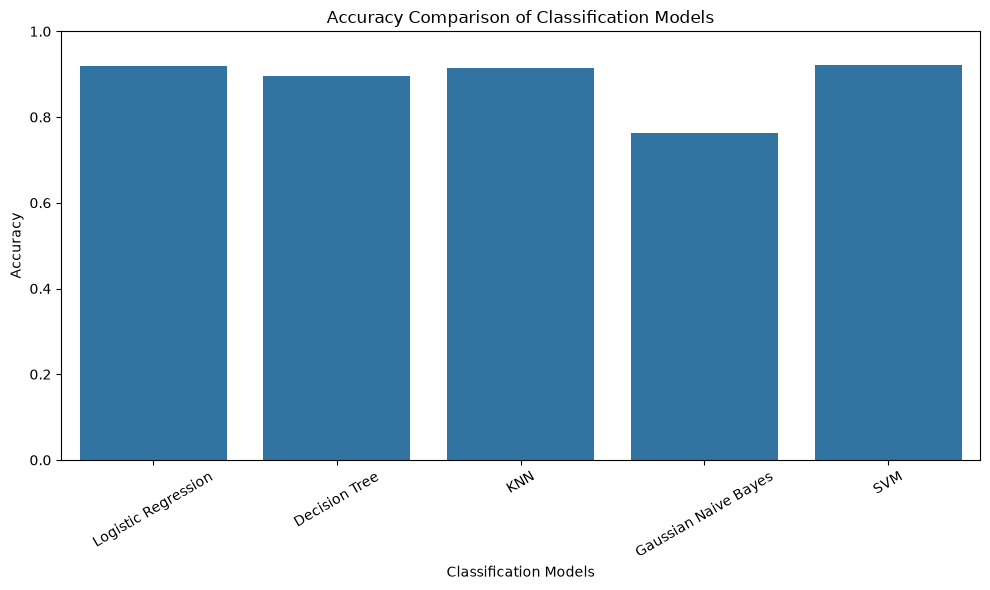

In [30]:

# Plot accuracy comparison of all five classification models

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_df,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison of Classification Models')
plt.xlabel('Classification Models')
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()



## Overall Model Comparison – Key Findings

Five classification algorithms were implemented and evaluated using six performance metrics: Accuracy, AUC Score, Precision, Recall and F1 Score, and Matthews Correlation Coefficient (MCC).

### Observations

1. Support Vector Machine achieved the highest accuracy of 92.10%, making it the best-performing model based on accuracy.

2. Logistic Regression achieved an accuracy of 91.92% and the highest AUC score of 0.9934.

3. K-Nearest Neighbors achieved an accuracy of 91.55%, showing competitive classification performance.

4. Decision Tree achieved an accuracy of 89.55%, performing slightly lower than the other three models.

5. Gaussian Naive Bayes achieved an accuracy of 76.30%, the lowest among the five algorithms.

### Conclusion

Based on the experimental results, Support Vector Machine is the best-performing classification algorithm in terms of accuracy, precision, recall, F1 score and MCC.

Logistic Regression achieved the highest AUC score, indicating excellent class discrimination.

Therefore, Support Vector Machine is selected as the best model based on overall classification performance.


In [31]:

# Import joblib for saving trained machine learning models
import joblib

# Create the Models folder if it does not already exist
models_path = project_path / "Models"
models_path.mkdir(parents=True, exist_ok=True)

# Store all trained models in a dictionary
models = {
    "logistic_regression.pkl": lr_model,
    "decision_tree.pkl": dt_model,
    "knn.pkl": knn_model,
    "naive_bayes.pkl": nb_model,
    "svm.pkl": svm_model
}

# Save each trained model inside the Models folder
for filename, model in models.items():
    joblib.dump(model, models_path / filename)
    print(f"Saved successfully: {filename}")

print("\nAll five models saved successfully!")


Saved successfully: logistic_regression.pkl
Saved successfully: decision_tree.pkl
Saved successfully: knn.pkl
Saved successfully: naive_bayes.pkl
Saved successfully: svm.pkl

All five models saved successfully!


In [32]:

# Save the fitted feature scaler
joblib.dump(scaler, models_path / "scaler.pkl")

# Save the target label encoder
joblib.dump(label_encoder, models_path / "label_encoder.pkl")

# Save the feature names in their original order
joblib.dump(X.columns.tolist(), models_path / "feature_names.pkl")

print("Scaler saved successfully!")
print("Label Encoder saved successfully!")
print("Feature Names saved successfully!")


Scaler saved successfully!
Label Encoder saved successfully!
Feature Names saved successfully!
